# Dimensionality Reduction and Data Visualization

Dataset "Materials and their Mechanical Properties"

from: https://www.kaggle.com/datasets/purushottamnawale/materials

From the previous laboratory assignment and the EDA process, a clean data table was obtained:

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

from sklearn.manifold import TSNE
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

from sklearn import set_config
set_config(display='text')

In [58]:
df = pd.read_csv(r"D:\KPI\Intelectual_data_analyse\materials_and_mechanical_properties\material.csv")
pd.set_option('display.max.rows', 5)

df['Use'] = (
    (df['Su'].between(292, 683)) &
    (df['Sy'].between(212, 494)) &
    (df['E'].between(196650, 217350)) &
    (df['G'].between(47400, 110600)) &
    (df['mu'].between(0.225, 0.375)) &
    (df['Ro'].between(6288, 9432))
).map({True: 'Yes', False: 'No'})

df

,Material,Su,Sy,E,G,mu,Ro,Use
0,ANSI Steel SAE 1015 as-rolled,421,314,207000,79000,0.30,7860,Yes
1,ANSI Steel SAE 1015 normalized,424,324,207000,79000,0.30,7860,Yes
...,...,...,...,...,...,...,...,...
1550,JIS Malleable cast iron,400,180,160000,64000,0.27,7160,No
1551,JIS Malleable cast iron,500,260,160000,64000,0.27,7160,No


**Training an SVM model to compare classification results before and after PCA.**

## Train Test Split

In [59]:
X = df[['Su', 'Sy', 'E', 'G', 'mu', 'Ro']]
X.head(5)

,Su,Sy,E,G,mu,Ro
0,421,314,207000,79000,0.3,7860
1,424,324,207000,79000,0.3,7860
2,386,284,207000,79000,0.3,7860
3,448,331,207000,79000,0.3,7860
4,441,346,207000,79000,0.3,7860


In [60]:
y = df['Use']
print(type(X), type(y))
print(X.shape, y.shape)

<class 'pandas.DataFrame'> <class 'pandas.Series'>
(1552, 6) (1552,)


In [61]:
# from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

## Support Vector Machine (SVM)

In [46]:
# Standardize the Variables
# SVM is very sensitive to feature scaling. StandardScaler() is the most common choice for SVM

scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

**Gridsearch**

In [47]:
param_grid = {'C': [0.1, 1, 10, 100, 1000], 'gamma': [1,0.1,0.01,0.001,0.0001], 'kernel': ['rbf']}

In [48]:
grid = GridSearchCV(SVC(), param_grid, cv=5,refit=True)

In [49]:
grid.fit(scaled_X_train,y_train)

GridSearchCV(cv=5, estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100, 1000],
                         'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
                         'kernel': ['rbf']})

In [50]:
grid.best_params_

{'C': 100, 'gamma': 1, 'kernel': 'rbf'}

In [51]:
grid.best_estimator_

SVC(C=100, gamma=1)

In [52]:
grid_predictions = grid.predict(scaled_X_test)

## Model Evaluation

In [53]:
print(confusion_matrix(y_test,grid_predictions))

[[223   2]
 [  0  86]]


In [54]:
print(classification_report(y_test,grid_predictions))
print('accuracy: ' f"{accuracy_score(y_test,grid_predictions):.2%}")

              precision    recall  f1-score   support

          No       1.00      0.99      1.00       225
         Yes       0.98      1.00      0.99        86

    accuracy                           0.99       311
   macro avg       0.99      1.00      0.99       311
weighted avg       0.99      0.99      0.99       311

accuracy: 99.36%


We obtained the prediction result from the SVM model prior to PCA.

## Principal Component Analysis (PCA)

In [55]:
## from sklearn.decomposition import PCA
## from sklearn.pipeline import Pipeline

In [63]:
# Дані
## X = df[['Su', 'Sy', 'E', 'G', 'mu', 'Ro']]
## y = df['Use']
## X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Базова модель: SVM без PCA (але зі скейлом)
pipe_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC())])

# Модель з PCA(0.95) + SVM
pipe_pca_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, svd_solver="full", random_state=42)), 
    ("classifier", SVC())])

# Крос-валідація для порівняння
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_svm = cross_val_score(pipe_svm, X_train, y_train, cv=cv, scoring="accuracy")
cv_pca_svm = cross_val_score(pipe_pca_svm, X_train, y_train, cv=cv, scoring="accuracy")

print("CV accuracy (mean±std)")
print(f"  SVM (no PCA):      {cv_svm.mean():.4f} ± {cv_svm.std():.4f}")
print(f"  PCA(0.95)+SVM:     {cv_pca_svm.mean():.4f} ± {cv_pca_svm.std():.4f}")

CV accuracy (mean±std)
  SVM (no PCA):      0.9275 ± 0.0151
  PCA(0.95)+SVM:     0.9194 ± 0.0115


In [64]:
# Навчання на train і оцінка на test + таймінги
def fit_eval(pipeline, X_train, y_train, X_test, y_test, label="model"):
    t0 = time.perf_counter()
    pipeline.fit(X_train, y_train)
    t1 = time.perf_counter()
    y_pred = pipeline.predict(X_test)
    t2 = time.perf_counter()
    acc = accuracy_score(y_test, y_pred)
    print(f"\n{label}")
    if "pca" in dict(pipeline.named_steps):
        pca = pipeline.named_steps["pca"]
        print(f"  PCA kept components: {pca.n_components_} (of {X.shape[1]})")
        print(f"  Explained variance sum: {pca.explained_variance_ratio_.sum():.3f}")
    print(f"  Test accuracy: {acc:.4f}")
    print(f"  Fit time: {t1 - t0:.4f}s | Predict time: {t2 - t1:.6f}s")
    print("  Confusion matrix:\n", confusion_matrix(y_test, y_pred))
    print("  Classification report:\n", classification_report(y_test, y_pred, digits=4))

fit_eval(pipe_svm, X_train, y_train, X_test, y_test, label="SVM (no PCA)")
fit_eval(pipe_pca_svm, X_train, y_train, X_test, y_test, label="PCA(0.95)+SVM")


SVM (no PCA)
  Test accuracy: 0.9357
  Fit time: 0.0281s | Predict time: 0.009723s
  Confusion matrix:
 [[205  20]
 [  0  86]]
  Classification report:
               precision    recall  f1-score   support

          No     1.0000    0.9111    0.9535       225
         Yes     0.8113    1.0000    0.8958        86

    accuracy                         0.9357       311
   macro avg     0.9057    0.9556    0.9247       311
weighted avg     0.9478    0.9357    0.9375       311


PCA(0.95)+SVM
  PCA kept components: 4 (of 6)
  Explained variance sum: 0.953
  Test accuracy: 0.9260
  Fit time: 0.0505s | Predict time: 0.023566s
  Confusion matrix:
 [[202  23]
 [  0  86]]
  Classification report:
               precision    recall  f1-score   support

          No     1.0000    0.8978    0.9461       225
         Yes     0.7890    1.0000    0.8821        86

    accuracy                         0.9260       311
   macro avg     0.8945    0.9489    0.9141       311
weighted avg     0.9417    0

Висновок: якість класифікації зменшилася, кількість необхідних ознак зменшилася від шести до чотирьох та час навчання моделі змінився на гірше. 

# Dimensionality reduction to 2D with t-SNE

t-distributed Stochastic Neighbor Embedding

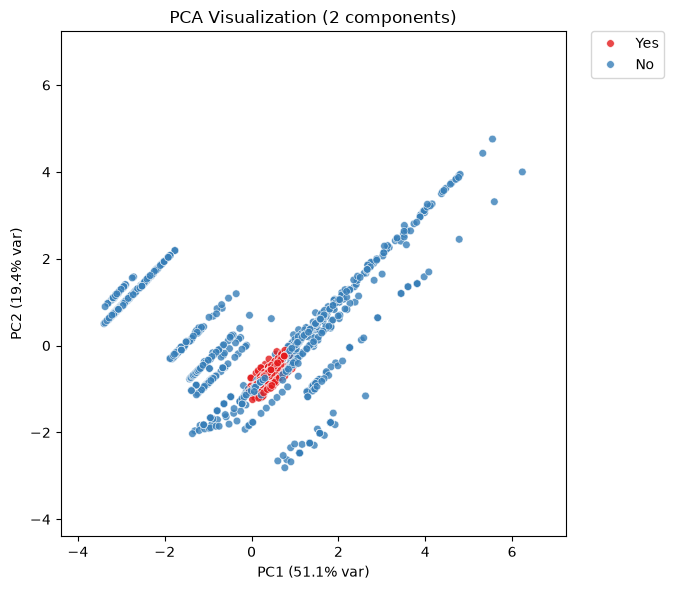

In [68]:
X_scaled = scaler.transform(X)

pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(X_scaled)

pca_result_df = pd.DataFrame({
    'pca_1': pca_result[:, 0], 
    'pca_2': pca_result[:, 1], 
    'label': y
})

# Побудова графіку
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    x='pca_1', y='pca_2', 
    hue='label', data=pca_result_df, 
    ax=ax, s=30, palette='Set1', alpha=0.8
)

ax.set_title('PCA Visualization (2 components)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)')

lim = (pca_result.min() - 1, pca_result.max() + 1)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect('equal')
ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.0)

plt.tight_layout()
plt.show()

**PCA** є лінійним методом. Видно, що класи на графіку PCA сильно накладаються, це означає, що лінійними комбінаціями механічних властивостей (`Su`, `Sy`, `E`, `G`, `mu`, `Ro`) важко розділити класи, саме тому випробування SVM з ядром або нелінійними підходами дає кращий результат.

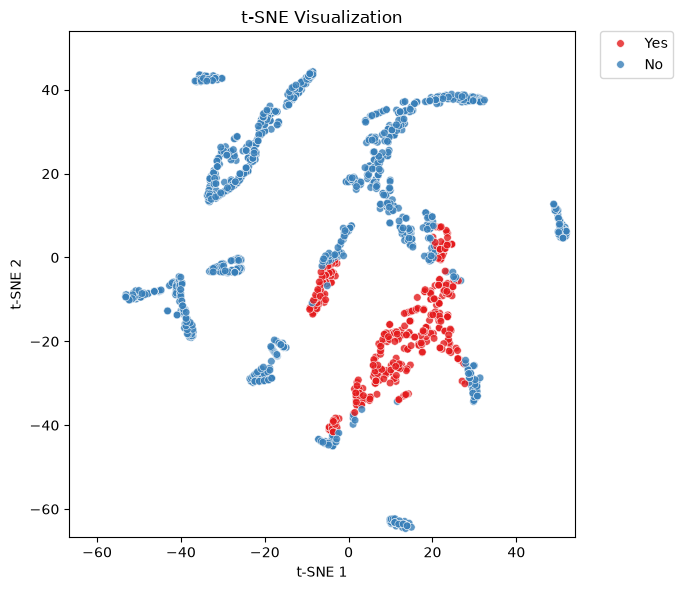

In [69]:
tsne = TSNE(
    n_components=2, 
    init="pca", 
    learning_rate='auto', 
    perplexity=30,
    random_state=42
)
tsne_result = tsne.fit_transform(X_scaled)

tsne_result_df = pd.DataFrame({
    'tsne_1': tsne_result[:, 0], 
    'tsne_2': tsne_result[:, 1], 
    'label': y
})

# Побудова графіку
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    x='tsne_1', y='tsne_2', 
    hue='label', data=tsne_result_df, 
    ax=ax, s=30, palette='Set1', alpha=0.8
)

ax.set_title('t-SNE Visualization')
ax.set_xlabel('t-SNE 1')
ax.set_ylabel('t-SNE 2')

lim = (tsne_result.min() - 2, tsne_result.max() + 2)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect('equal')
ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.0)

plt.tight_layout()
plt.show()

**t-SNE** є нелінійним методом. Він добре показує локальні кластери та структуру даних у вигляді скупчень. Видно, що класи гарно групуються на t-SNE, що означає, що модель машинного навчання має потенціал для успішної класифікації.

In [70]:
print("\nПараметри t-SNE:")
for k, v in tsne.get_params().items():
    print(f"{k} = {v}")


Параметри t-SNE:
angle = 0.5
early_exaggeration = 12.0
init = pca
learning_rate = auto
max_iter = 1000
method = barnes_hut
metric = euclidean
metric_params = None
min_grad_norm = 1e-07
n_components = 2
n_iter_without_progress = 300
n_jobs = None
perplexity = 30
random_state = 42
verbose = 0


# Cluster analysis

## K-means Clustering

In [76]:
import matplotlib.cm as cm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

In [79]:
%reset

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA
from sklearn.svm import SVC

from sklearn.pipeline import Pipeline

from sklearn.manifold import TSNE
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import GridSearchCV

from sklearn import set_config
set_config(display='text')

import matplotlib.cm as cm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

In [2]:
df = pd.read_csv(r"D:\KPI\Intelectual_data_analyse\materials_and_mechanical_properties\material.csv")
pd.set_option('display.max.rows', 5)

df['Use'] = (
    (df['Su'].between(292, 683)) &
    (df['Sy'].between(212, 494)) &
    (df['E'].between(196650, 217350)) &
    (df['G'].between(47400, 110600)) &
    (df['mu'].between(0.225, 0.375)) &
    (df['Ro'].between(6288, 9432))
).map({True: 'Yes', False: 'No'})

df

,Material,Su,Sy,E,G,mu,Ro,Use
0,ANSI Steel SAE 1015 as-rolled,421,314,207000,79000,0.30,7860,Yes
1,ANSI Steel SAE 1015 normalized,424,324,207000,79000,0.30,7860,Yes
...,...,...,...,...,...,...,...,...
1550,JIS Malleable cast iron,400,180,160000,64000,0.27,7160,No
1551,JIS Malleable cast iron,500,260,160000,64000,0.27,7160,No


In [10]:
X = df[['Su', 'Sy', 'E', 'G', 'mu', 'Ro']]
X.head(5)
y = df['Use']

## Elbow plot

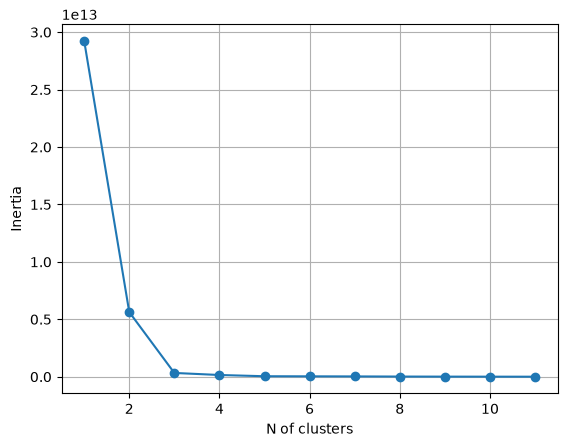

In [5]:
Error =[]
for i in range(1, 12):
    kmeans = KMeans(n_clusters = i) # ці два рядки і відповідають за k-means алгоритм
    kmeans.fit(X) # ці два рядки і відповідають за k-means алгоритм
    Error.append(kmeans.inertia_)

plt.plot(range(1, 12), Error, marker = 'o')
plt.xlabel('N of clusters')
plt.ylabel('Inertia')
plt.grid()
plt.show()

## Silhouette score

Показує: наскільки об’єкти близькі до свого кластера і віддалені від інших кластерів

Діапазон значень: від –1 до 1

Близько +1 → об’єкти добре згруповані

Близько 0 → кластери накладаються

Менше 0 → можливо, об’єкт віднесено не до свого кластера

Потрібно для: кількісної оцінки якості кластеризації при різних k

Ідея: обираємо таке k, де середній silhouette score найбільший

In [6]:
for i in range(2, 7):
    kmeans = KMeans(n_clusters=i, random_state=0)
    kmeans_labels = kmeans.fit_predict(X)

    silhouette_avg = silhouette_score(X, kmeans_labels)
    print("For n_clusters =", i, " silhouette average:", silhouette_avg)

For n_clusters = 2  silhouette average: 0.9132948434141593
For n_clusters = 3  silhouette average: 0.8932982158255464
For n_clusters = 4  silhouette average: 0.8883713237601811
For n_clusters = 5  silhouette average: 0.8950662324227255
For n_clusters = 6  silhouette average: 0.8999235610845594


## Clustering

Найбільший середній silhouette score при n_clusters = 2

З лекції наведений приклад коду:

In [ ]:
kmeans = KMeans(n_clusters=3)
kmeans.fit(data[0])
centers = kmeans.cluster_centers_
labels = kmeans.labels_

f, (ax1, ax2) = plt.subplots(1, 2, sharey=True)
ax1.set_title('K Means')
ax1.scatter(data[0][:,0],data[0][:,1],c=labels)
ax2.set_title("Original")
ax2.scatter(data[0][:,0],data[0][:,1],c=data[1])
ax1.scatter(centers[:, 0], centers[:, 1], marker='o', color = 'red', s = 100, edgecolor='black')
plt.show()

Але він розрахований на штучний 2D-датасет, де дані одразу мають лише 2 стовпчики, тому там можна напряму брати `data[0][:, 0]` і `data[0][:, 1]` як осі `X` та `Y` і одразу вираховувати центроїди у 2D. 

У моєму випадку датасет має 6 вимірів (Su, Sy, E, G, mu, Ro). Напряму побудувати 2D-графік із центроїдами для 6 ознак неможливо. Щоб порівняти кластери з оригінальними класами поруч на графіках і показати центроїди, нам потрібно знизити розмірність за допомогою PCA до 2 компонент. При цьому сам алгоритм `k-means` краще навчити на повному масштабованому просторі (6D), що ми і зробили, а вже потім за допомогою того ж самого PCA перетворити і самі дані, і координати центроїдів у 2D-простір для візуалізації.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

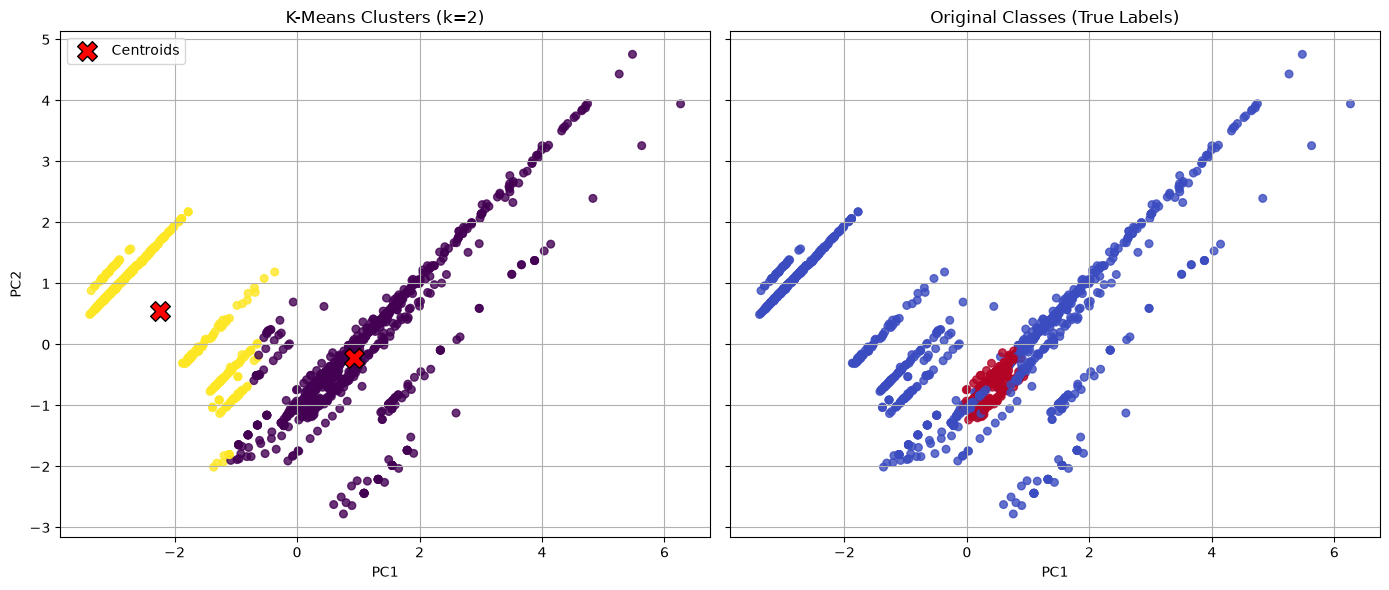

In [12]:
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=42, n_init=10)
kmeans.fit(X_scaled)

clusters = kmeans.labels_  
centers_6d = kmeans.cluster_centers_  

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

centers_pca = pca.transform(centers_6d)

y_numeric = y.map({'Yes': 1, 'No': 0})

# Побудова графіків (порівняння K-Means і оригінальних класів)
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
scatter1 = ax1.scatter(
    X_pca[:, 0], X_pca[:, 1], c=clusters, cmap='viridis', s=30, alpha=0.8
)
ax1.set_title('K-Means Clusters (k=2)')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker='X',
    color='red',
    s=200,
    edgecolor='black',
    label='Centroids',
)
ax1.legend()
ax1.grid(True)

scatter2 = ax2.scatter(
    X_pca[:, 0], X_pca[:, 1], c=y_numeric, cmap='coolwarm', s=30, alpha=0.8
)
ax2.set_title('Original Classes (True Labels)')
ax2.set_xlabel('PC1')
ax2.grid(True)

plt.tight_layout()
plt.show()

В оригінальному датасеті ми маємо класи у колонці `"Use"`: Так і Ні. ці класи визначені строгою математичною умовою, тоді як алгоритм k-means шукає сферичні кластери на основі мінімізації евклідової відстані до центроїдів, поділяючи простір «по центру мас» даних, незалежно від того, як саме задані логічні правила для `"Use"`

Відповідно, хоч у висновку k-means успішно розділив класи на два основних, нажаль, ці групи практично не перетинаються зі справжніми класами.

# Processing and classification of text data

In [13]:
%reset

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix,  accuracy_score
from sklearn.linear_model import LogisticRegression

In [2]:
df = pd.read_csv(r"D:\KPI\Intelectual_data_analyse\materials_and_mechanical_properties\Data.csv")
pd.set_option('display.max.rows', 15)
df

,Std,ID,Material,Heat treatment,Su,Sy,A5,Bhn,E,G,mu,Ro,pH,Desc,HV
0,ANSI,D8894772B88F495093C43AF905AB6373,Steel SAE 1015,as-rolled,421,314,39.0,126.0,207000,79000,0.30,7860,NaN,NaN,NaN
1,ANSI,05982AC66F064F9EBC709E7A4164613A,Steel SAE 1015,normalized,424,324,37.0,121.0,207000,79000,0.30,7860,NaN,NaN,NaN
2,ANSI,356D6E63FF9A49A3AB23BF66BAC85DC3,Steel SAE 1015,annealed,386,284,37.0,111.0,207000,79000,0.30,7860,NaN,NaN,NaN
3,ANSI,1C758F8714AC4E0D9BD8D8AE1625AECD,Steel SAE 1020,as-rolled,448,331,36.0,143.0,207000,79000,0.30,7860,NaN,NaN,NaN
4,ANSI,DCE10036FC1946FC8C9108D598D116AD,Steel SAE 1020,normalized,441,346,35.8,131.0,207000,79000,0.30,7860,550.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1547,JIS,512A80EC21EA416BA2725B38BA8096EF,Nodular cast iron,NaN,600,370,NaN,NaN,169000,70000,0.20,7160,480.0,Nodular cast iron,210.0
1548,JIS,38526441BA8741CA979DBF870D0B8A9B,Nodular cast iron,NaN,700,420,NaN,NaN,169000,70000,0.20,7160,560.0,Nodular cast iron,230.0
1549,JIS,CAC03D7EB1AA45E68EFF92A2EF4C3D9B,Nodular cast iron,NaN,800,480,NaN,NaN,169000,70000,0.20,7160,600.0,Nodular cast iron,240.0
1550,JIS,45C82A36EC644F8BB6170A99ED819B62,Malleable cast iron,NaN,400,180,4.0,NaN,160000,64000,0.27,7160,300.0,Malleable cast iron,220.0


In [3]:
df.info()
df.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 1552 entries, 0 to 1551
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Std             1552 non-null   str    
 1   ID              1552 non-null   str    
 2   Material        1552 non-null   str    
 3   Heat treatment  802 non-null    str    
 4   Su              1552 non-null   int64  
 5   Sy              1552 non-null   str    
 6   A5              1346 non-null   float64
 7   Bhn             463 non-null    float64
 8   E               1552 non-null   int64  
 9   G               1552 non-null   int64  
 10  mu              1552 non-null   float64
 11  Ro              1552 non-null   int64  
 12  pH              193 non-null    float64
 13  Desc            981 non-null    str    
 14  HV              165 non-null    float64
dtypes: float64(5), int64(4), str(6)
memory usage: 299.1 KB


Std                  8
ID                1552
Material          1225
Heat treatment      44
Su                 309
Sy                 291
A5                  98
Bhn                143
E                   43
G                   33
mu                  11
Ro                  35
pH                  53
Desc                83
HV                  48
dtype: int64

In [4]:
Clean_Table = df.drop(['ID', 'Heat treatment', 'Su', 'Sy', 'E','A5', 'Bhn', 'G', 'mu', 'Ro', 'pH', 'Desc', 'HV'],axis = 1)
Clean_Table.head(5)

,Std,Material
0,ANSI,Steel SAE 1015
1,ANSI,Steel SAE 1015
2,ANSI,Steel SAE 1015
3,ANSI,Steel SAE 1020
4,ANSI,Steel SAE 1020


In [5]:
Clean_Table.shape

(1552, 2)

In [6]:
from collections import Counter
Counter( Clean_Table['Std'])

Counter({'ANSI': 622,
         'GOST': 323,
         'CSN': 172,
         'DIN': 114,
         'ISO': 91,
         'NF': 91,
         'BS': 72,
         'JIS': 67})

In [7]:
#!pip install wordcloud
from wordcloud import WordCloud

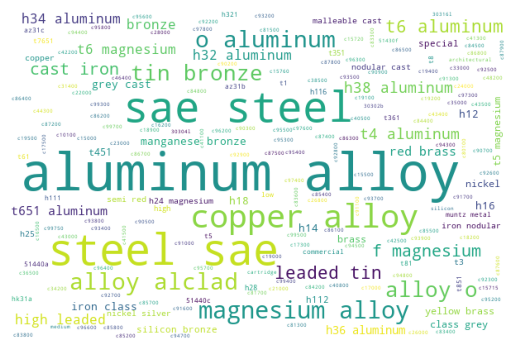

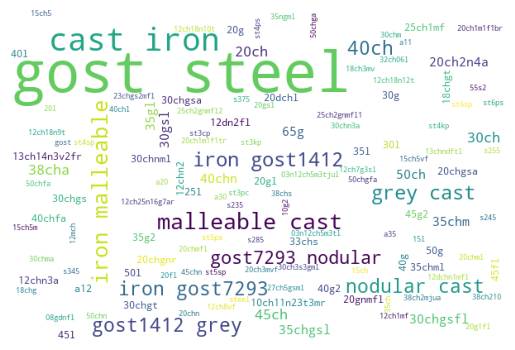

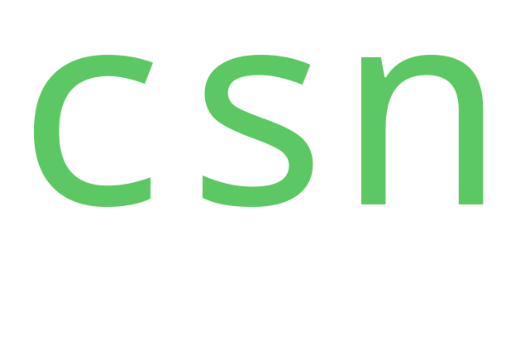

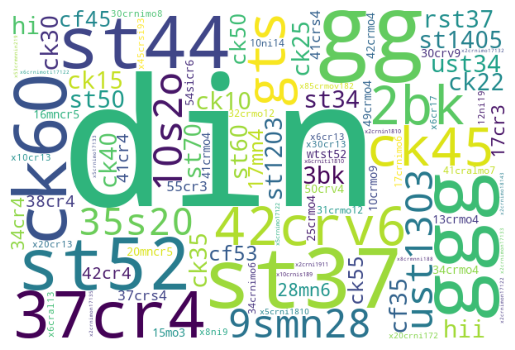

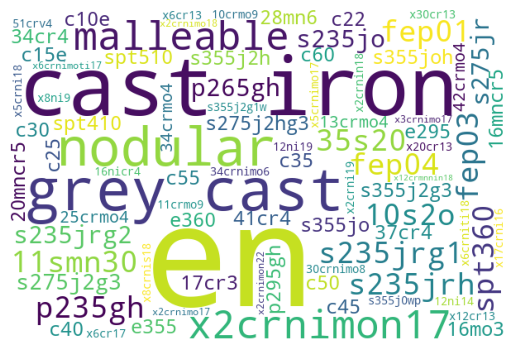

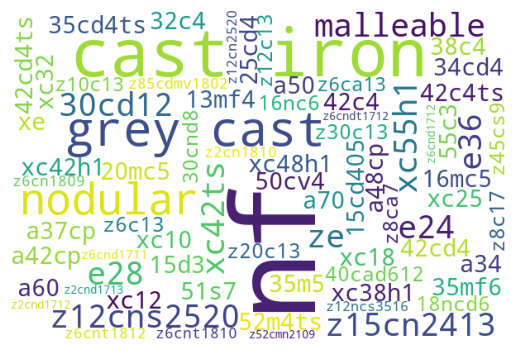

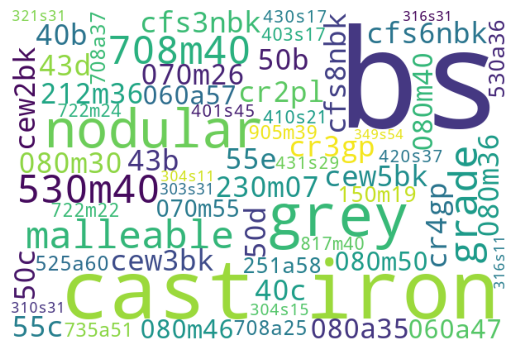

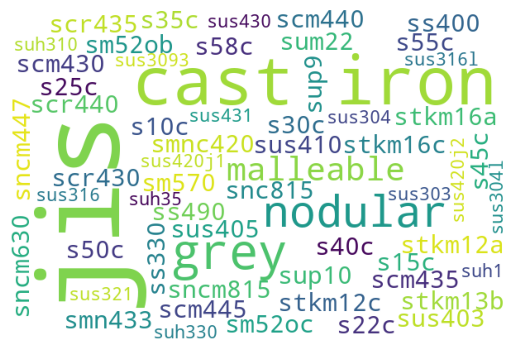

In [8]:
def visualize(label):
    text = ''
    for msg in Clean_Table[Clean_Table['Std'] == label]['Material']:
        msg = msg.lower()
        text += msg + ' '
    wordcloud = WordCloud(width=600, height=400, background_color="white").generate(text)
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.show()

visualize('ANSI')
visualize('GOST')
visualize('CSN')
visualize('DIN')
visualize('ISO')
visualize('NF')
visualize('BS')
visualize('JIS')

## Train Test Split

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(Clean_Table['Material'], Clean_Table['Std'], test_size=0.20)

In [10]:
print(X_train.shape, y_train.shape)

(1241,) (1241,)


## Vectorization

**CountVectorizer** 

In [11]:
vectorizer = CountVectorizer()
X_train_transformed = vectorizer.fit_transform(X_train)
X_test_transformed = vectorizer.transform(X_test)

## Model

In [12]:
clf = MultinomialNB(alpha=0.1)
clf.fit(X_train_transformed, y_train)
y_pred = clf.predict(X_test_transformed)

In [13]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        ANSI       1.00      0.98      0.99       120
          BS       1.00      0.77      0.87        13
         CSN       1.00      1.00      1.00        42
         DIN       1.00      1.00      1.00        20
        GOST       1.00      1.00      1.00        65
         ISO       1.00      0.88      0.93        16
         JIS       0.60      1.00      0.75        12
          NF       1.00      0.96      0.98        23

    accuracy                           0.97       311
   macro avg       0.95      0.95      0.94       311
weighted avg       0.98      0.97      0.98       311



In [14]:
print(confusion_matrix(y_test, y_pred))

[[118   0   0   0   0   0   2   0]
 [  0  10   0   0   0   0   3   0]
 [  0   0  42   0   0   0   0   0]
 [  0   0   0  20   0   0   0   0]
 [  0   0   0   0  65   0   0   0]
 [  0   0   0   0   0  14   2   0]
 [  0   0   0   0   0   0  12   0]
 [  0   0   0   0   0   0   1  22]]


In [22]:
print('accuracy: ' f"{accuracy_score(y_test,y_pred):.2%}")

accuracy: 97.43%


## Vectorization

**with TFIDF**

In [16]:
tfidf_vectorizer = TfidfVectorizer()

tfidf_train = tfidf_vectorizer.fit_transform(X_train)
tfidf_test =  tfidf_vectorizer.transform(X_test)

clf = LogisticRegression().fit(tfidf_train, y_train)

predicted = clf.predict(tfidf_test)
print(classification_report(y_test, predicted))

              precision    recall  f1-score   support

        ANSI       0.98      0.98      0.98       120
          BS       1.00      0.77      0.87        13
         CSN       1.00      1.00      1.00        42
         DIN       1.00      1.00      1.00        20
        GOST       0.97      1.00      0.98        65
         ISO       1.00      0.88      0.93        16
         JIS       0.80      1.00      0.89        12
          NF       1.00      0.96      0.98        23

    accuracy                           0.97       311
   macro avg       0.97      0.95      0.95       311
weighted avg       0.98      0.97      0.97       311



In [21]:
print(confusion_matrix(y_test, predicted))

[[118   0   0   0   2   0   0   0]
 [  0  10   0   0   0   0   3   0]
 [  0   0  42   0   0   0   0   0]
 [  0   0   0  20   0   0   0   0]
 [  0   0   0   0  65   0   0   0]
 [  2   0   0   0   0  14   0   0]
 [  0   0   0   0   0   0  12   0]
 [  1   0   0   0   0   0   0  22]]


In [20]:
print('accuracy: ' f"{accuracy_score(y_test,predicted):.2%}")

accuracy: 97.43%
